# Results Dashboard

This notebook aggregates experiment outputs from the five experiment scripts in [experiments](experiments).

Expected artifacts per run:
- results.json
- weights/*.npy

Default output root: outputs/

In [2]:
from pathlib import Path
import json
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

CANDIDATE_OUTPUT_ROOTS = [
    Path('outputs'),
    Path('experiments') / 'outputs',
]
OUTPUT_ROOTS = [p for p in CANDIDATE_OUTPUT_ROOTS if p.exists()] or [CANDIDATE_OUTPUT_ROOTS[0]]
OUTPUT_ROOTS

[PosixPath('experiments/outputs')]

In [3]:
def list_run_dirs(exp_name: str):
    runs = []
    for root in OUTPUT_ROOTS:
        exp_dir = root / exp_name
        if exp_dir.exists():
            runs.extend([p for p in exp_dir.iterdir() if p.is_dir()])
    return runs

def latest_run_dir(exp_name: str):
    runs = list_run_dirs(exp_name)
    if not runs:
        return None
    return max(runs, key=lambda p: p.stat().st_mtime)

def load_results_json(path: Path):
    with path.open('r') as f:
        return json.load(f)

def flatten_model_rows(exp_name, run_dir, node):
    rows = []

    def walk(obj, prefix=''):
        if isinstance(obj, dict):
            if 'mean_best_val_acc' in obj and 'std_best_val_acc' in obj:
                rows.append({
                    'experiment': exp_name,
                    'run_dir': str(run_dir),
                    'scope': prefix or 'root',
                    'mean_best_val_acc': obj['mean_best_val_acc'],
                    'std_best_val_acc': obj['std_best_val_acc'],
                })
            for k, v in obj.items():
                new_prefix = f'{prefix}/{k}' if prefix else k
                walk(v, new_prefix)

    walk(node)
    return rows

In [4]:
EXPERIMENTS = [
    'exp1_alignment_ablation',
    'exp2_support_coverage',
    'exp3_spectrum_independence',
    'exp4_robustness',
    'exp5_raw_sar_classification',
]

records = []
meta_records = []
for exp in EXPERIMENTS:
    run_dir = latest_run_dir(exp)
    if run_dir is None:
        continue
    result_file = run_dir / 'results.json'
    if not result_file.exists():
        continue
    payload = load_results_json(result_file)

    rows = flatten_model_rows(exp, run_dir, payload.get('results', {}))
    records.extend(rows)

    meta = payload.get('metadata', {})
    meta_records.append({
        'experiment': exp,
        'run_dir': str(run_dir),
        'max_samples': meta.get('max_samples'),
        'raw_dataset_size': meta.get('raw_dataset_size'),
        'raw_subset_size': meta.get('raw_subset_size'),
        'focused_subset_size': meta.get('focused_subset_size'),
        'target_pairs': meta.get('target_pairs'),
        'layers_grid': meta.get('layers_grid'),
    })

df = pd.DataFrame(records)
meta_df = pd.DataFrame(meta_records)
df

,experiment,run_dir,scope,mean_best_val_acc,std_best_val_acc
0,exp1_alignment_ablation,experiments/outputs/exp1_alignment_ablation/et...,aligned,0.95,0.05
1,exp1_alignment_ablation,experiments/outputs/exp1_alignment_ablation/et...,standard,0.95,0.05


In [5]:
if df.empty:
    print('No experiment results found under outputs/. Run scripts first.')
else:
    summary = df.sort_values(['experiment', 'scope']).reset_index(drop=True)
    display(summary)

if not meta_df.empty:
    key_cols = [
        'experiment',
        'run_dir',
        'target_pairs',
        'layers_grid',
        'raw_dataset_size',
        'raw_subset_size',
        'focused_subset_size',
        'max_samples',
    ]
    display(meta_df[key_cols].sort_values('experiment').reset_index(drop=True))

,experiment,run_dir,scope,mean_best_val_acc,std_best_val_acc
0,exp1_alignment_ablation,experiments/outputs/exp1_alignment_ablation/et...,aligned,0.95,0.05
1,exp1_alignment_ablation,experiments/outputs/exp1_alignment_ablation/et...,standard,0.95,0.05


,experiment,run_dir,target_pairs,layers_grid,raw_dataset_size,raw_subset_size,focused_subset_size,max_samples
0,exp1_alignment_ablation,experiments/outputs/exp1_alignment_ablation/et...,None,None,None,None,None,None


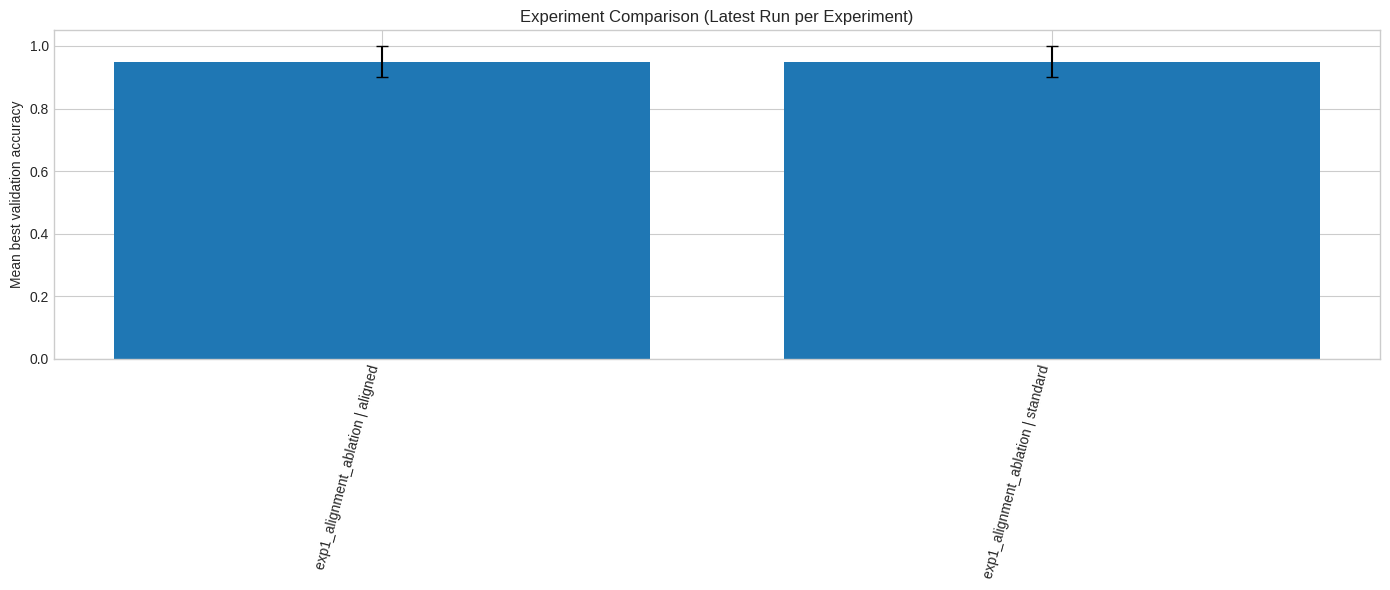

In [6]:
if not df.empty:
    # Focused comparison rows where scope ends with aligned/standard/coupled.
    plot_df = df[df['scope'].str.contains('aligned|standard|coupled|alternating_factorized', regex=True)].copy()
    if not plot_df.empty:
        labels = plot_df['experiment'] + ' | ' + plot_df['scope']
        x = np.arange(len(plot_df))

        fig, ax = plt.subplots(figsize=(14, 6))
        ax.bar(x, plot_df['mean_best_val_acc'], yerr=plot_df['std_best_val_acc'], capsize=4)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=75, ha='right')
        ax.set_ylim(0.0, 1.05)
        ax.set_ylabel('Mean best validation accuracy')
        ax.set_title('Experiment Comparison (Latest Run per Experiment)')
        plt.tight_layout()
        plt.show()

## Fold Curves (Aligned vs Standard)

This plot shows per-fold training/validation performance for a selected run.
- Left subplot: aligned model
- Right subplot: standard model
- Train metric: line
- Validation metric: points

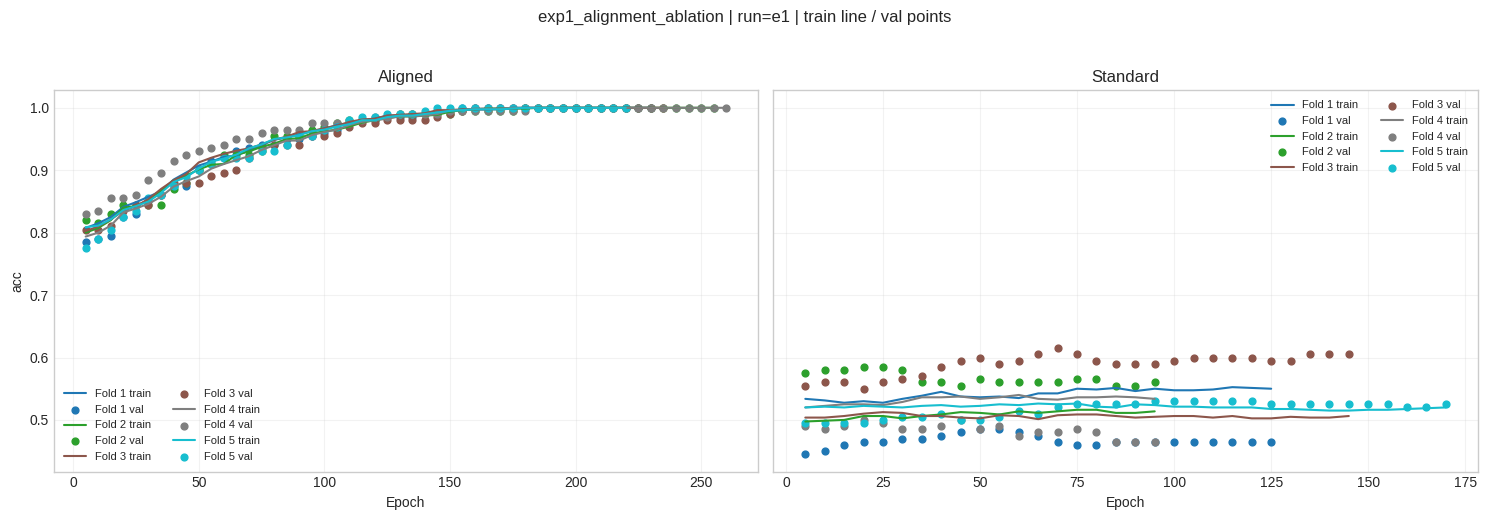

In [14]:
def _fold_dir_index(path: Path) -> int:
    name = path.name
    if not name.startswith('fold_'):
        return 10**9
    tail = name.split('fold_', 1)[1]
    try:
        return int(tail)
    except ValueError:
        return 10**9


def _collect_results_for_run(run_dir: Path):
    fold_dirs = sorted(
        [p for p in run_dir.iterdir() if p.is_dir() and p.name.startswith('fold_')],
        key=_fold_dir_index,
    ) if run_dir.exists() else []

    # New layout: run_dir/fold_i/results.json
    if fold_dirs:
        merged = {
            'aligned': {'fold_metrics': []},
            'standard': {'fold_metrics': []},
        }
        loaded_any = False

        for fd in fold_dirs:
            result_file = fd / 'results.json'
            if not result_file.exists():
                continue
            payload = load_results_json(result_file)
            results = payload.get('results', {})
            loaded_any = True

            fold_idx = _fold_dir_index(fd)
            for model_key in ('aligned', 'standard'):
                block = results.get(model_key, {})
                for fold in block.get('fold_metrics', []):
                    fold_copy = dict(fold)
                    if fold_copy.get('fold') is None and fold_idx < 10**9:
                        fold_copy['fold'] = fold_idx
                    merged[model_key]['fold_metrics'].append(fold_copy)

        if loaded_any:
            for model_key in ('aligned', 'standard'):
                merged[model_key]['fold_metrics'] = sorted(
                    merged[model_key]['fold_metrics'],
                    key=lambda f: f.get('fold', 10**9),
                )
            return merged, f"{run_dir.name} (merged fold_*)"

    # Original layout: run_dir/results.json
    result_file = run_dir / 'results.json'
    if not result_file.exists():
        return None, None

    payload = load_results_json(result_file)
    return payload.get('results', {}), run_dir.name


def plot_two_panel_fold_curves(exp_name, run_name, use_fold=False, metric='acc'):
    candidates = [p for p in list_run_dirs(exp_name) if p.name == run_name]
    run_dir = max(candidates, key=lambda p: p.stat().st_mtime) if candidates else None

    if run_dir is None:
        print(f'No run found for {exp_name} with run_name={run_name}.')
        return

    results, run_label = _collect_results_for_run(run_dir)
    if results is None:
        print(f'Missing results.json in {run_dir} (or its fold_* children)')
        return

    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    model_keys = [('aligned', 'Aligned'), ('standard', 'Standard')]

    for ax, (model_key, title) in zip(axes, model_keys):
        model_block = results.get(model_key)
        if model_block is None:
            ax.set_title(f'{title} (missing)')
            ax.set_xlabel('Epoch')
            continue

        folds = model_block.get('fold_metrics', [])
        if not folds:
            ax.set_title(f'{title} (no fold history)')
            ax.set_xlabel('Epoch')
            continue

        colors = plt.cm.tab10(np.linspace(0.0, 1.0, max(len(folds), 1)))
        for i, fold in enumerate(folds):
            hist = fold.get('history', {})
            train_vals = np.array(hist.get(f'train_{metric}', []), dtype=float)
            val_vals = np.array(hist.get(f'val_{metric}', []), dtype=float)
            epochs = np.arange(1, len(train_vals) + 1)

            color = colors[i % len(colors)]
            train_mask = ~np.isnan(train_vals)
            val_mask = ~np.isnan(val_vals)

            ax.plot(
                epochs[train_mask],
                train_vals[train_mask],
                color=color,
                linewidth=1.5,
                label=f'Fold {fold.get("fold", i + 1)} train',
            )
            ax.scatter(
                epochs[val_mask],
                val_vals[val_mask],
                color=color,
                s=24,
                marker='o',
                label=f'Fold {fold.get("fold", i + 1)} val',
            )

        ax.set_title(title)
        ax.set_xlabel('Epoch')
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8, ncol=2)

    axes[0].set_ylabel(metric)
    fig.suptitle(f'{exp_name} | run={run_label} | train line / val points', y=1.03)
    plt.tight_layout()
    plt.show()


plot_two_panel_fold_curves(
    exp_name='exp1_alignment_ablation',
    run_name='e1',
    metric='acc',
    use_fold=False,
 )

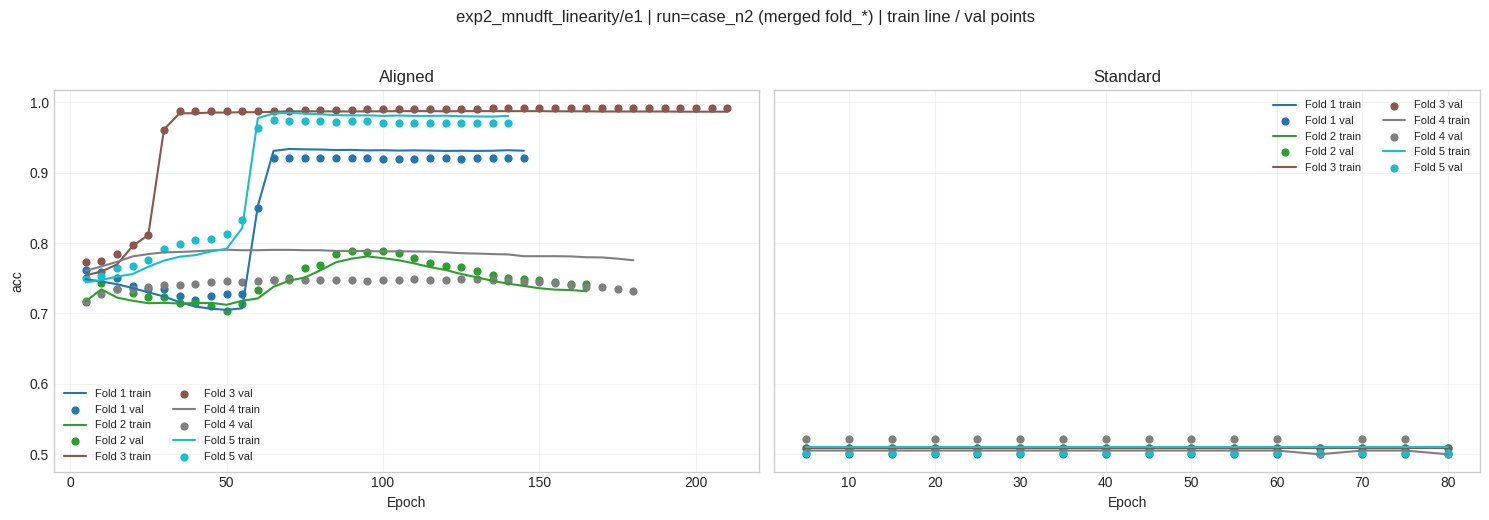

In [15]:
plot_two_panel_fold_curves(
    exp_name='exp2_mnudft_linearity/e1',
    run_name="case_n2",  # set to a specific run directory name like 'e1' if needed
    metric='acc',
    use_fold=True,
)

In [9]:
def count_weight_files(exp_name):
    run_dir = latest_run_dir(exp_name)
    if run_dir is None:
        return {'experiment': exp_name, 'run_dir': None, 'n_weight_files': 0}
    weights_dir = run_dir / 'weights'
    n = len(list(weights_dir.glob('*.npy'))) if weights_dir.exists() else 0
    return {'experiment': exp_name, 'run_dir': str(run_dir), 'n_weight_files': n}

wf = pd.DataFrame([count_weight_files(e) for e in EXPERIMENTS])
wf

,experiment,run_dir,n_weight_files
0,exp1_alignment_ablation,experiments/outputs/exp1_alignment_ablation/et...,4
1,exp2_support_coverage,None,0
2,exp3_spectrum_independence,None,0
3,exp4_robustness,None,0
4,exp5_raw_sar_classification,None,0
